# Which shell programs should get `ml.sh` manifests first?

`ml.sh` runs a program through a manifest (`src/shell/manifests/<program>.json`, `docs/spec/PROGRAM_MANIFEST.md`). The
question: of the programs past Claude Code sessions on this machine actually ran through their `Bash` tool, which
have no manifest yet and would pay back most?

**Privacy rule.** Transcripts can hold tokens and `.env` values inside commands. `count-programs.mjs` therefore emits
PROGRAM NAMES and numbers only. A name is kept only if it matches `^[A-Za-z0-9][A-Za-z0-9._+-]{0,39}$` after taking the
basename of a path, and appears in at least 2 distinct sessions; everything else is folded into one `(other)` count.
No command text, argument, path or tool output is stored, printed or committed (the only per-name exception is a
fixed watch list typed on the command line, exempt from the two-session rule).

**Method.**

- Input: every `*.jsonl` under `~/.claude/projects/`, recursively. A subagent transcript counts toward its parent
  session. Each `Bash` `tool_use` is counted once by its id (resumed sessions copy earlier messages).
- A quote-aware tokenizer (single and double quotes, backslash escapes, heredoc bodies skipped to their terminator)
  splits the command into simple commands on `;` `&&` `||` `|` `&` newlines and parentheses. `$( ... )`, backticks
  and `<( ... )` bodies are parsed recursively and their commands counted too. A command it cannot parse
  (unterminated quote, paren or heredoc) is counted in `parse_failures` and contributes nothing.
- Per simple command: leading `VAR=value` dropped; `env sudo nohup time nice caffeinate xargs timeout` are counted
  as wrappers (own table) and the program they run is counted; `cd export source .` and shell keywords are skipped;
  `echo`/`printf` are kept and tagged `builtin`. One call = one simple command, so `a | b | c` is three calls.
- `node <script>`, `npm run <x>`, `npx <x>`, `python3 <x>` / `-m <x>`, `uv run <x>` count under the interpreter AND in
  a sub-name table (the repo's own tools, not manifest candidates).
- `denied` is read from the matching `tool_result` (`tool_use_id`): `is_error` plus the fixed leading phrase of the
  auto-mode classifier's refusal ("Permission for this action ...") or of a user rejection ("The user doesn't want to
  proceed" / "rejected"). The phrase is matched, never kept.

In [1]:
import json, subprocess, tempfile
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import wmlnb

HERE = wmlnb.ROOT / "notebooks" / "shell"
EXTRACT = HERE / "data" / "shell-usage" / "programs.json"
WATCH = ["top", "ps", "vm_stat", "memory_pressure", "df", "du", "uptime", "sysctl", "lsof"]
pd.set_option("display.width", 160); pd.set_option("display.max_rows", 200)

def read_transcripts():
    with tempfile.TemporaryDirectory() as d:
        out = Path(d) / "out.json"
        subprocess.run(["node", str(HERE / "count-programs.mjs"), str(out), "--watch", ",".join(WATCH)], check=True, capture_output=True)
        r = json.loads(out.read_text())
    rows = [{"table": "corpus", **r["corpus"]}, {"table": "other", **r["other"]}, {"table": "subnames_other", **r["subnames_other"]}]
    rows += [{"table": "program", **p} for p in r["programs"]]
    rows += [{"table": "wrapper", **p} for p in r["wrappers"]]
    rows += [{"table": "sub", **p} for p in r["subnames"]]
    rows += [{"table": "manifest", "name": m} for m in r["manifests"]]
    return rows

rows = wmlnb.extract(EXTRACT, read_transcripts, source={"input": "~/.claude/projects/**/*.jsonl", "script": "notebooks/shell/count-programs.mjs", "watch": WATCH})
T = lambda t: pd.DataFrame([{k: v for k, v in r.items() if k != "table"} for r in rows if r["table"] == t])
corpus = T("corpus").iloc[0]
progs, wraps, subs, manifests = T("program"), T("wrapper"), T("sub"), T("manifest")
other = T("other").iloc[0]
pd.DataFrame(wmlnb.provenance(EXTRACT))

,extract,sha256,rows,extracted_at,commit,input,script,watch
0,notebooks/shell/data/shell-usage/programs.json,679fab1322480266,457,2026-11-17T17:15:59+00:00,d4ae4d443e92,~/.claude/projects/**/*.jsonl,notebooks/shell/count-programs.mjs,"[top, ps, vm_stat, memory_pressure, df, du, up..."


## Corpus

In [2]:
ext_calls = progs[progs.kind == "external"].calls.sum()
all_calls = progs.calls.sum() + other.calls
pd.Series({
    "top-level session transcripts": corpus.files_top_level,
    "subagent transcripts": corpus.files_subagent,
    "sessions (subagents folded into their parent)": corpus.sessions,
    "projects": corpus.projects,
    "Bash tool calls (unique ids)": corpus.bash_tool_uses,
    "simple commands after splitting": corpus.simple_commands,
    "parse failures (whole command skipped)": corpus.parse_failures,
    "tool results matched": corpus.tool_results_matched,
    "program names kept (>= 2 sessions)": len(progs),
    "(other): distinct names / calls": f"{other.names} / {other.calls}",
    "(other) share of program calls": f"{other.calls / all_calls:.2%}",
    "first / last call": f"{progs['first'].min()} / {progs['last'].max()}",
}).to_frame("value")

,value
top-level session transcripts,74
subagent transcripts,342
sessions (subagents folded into their parent),74
projects,10
Bash tool calls (unique ids),73885
simple commands after splitting,312982
parse failures (whole command skipped),235
tool results matched,73871
program names kept (>= 2 sessions),152
(other): distinct names / calls,374 / 1813


## The most-run external programs

Sorted by distinct sessions (calls break ties); builtins are left out here and tabled in the next cell.

In [3]:
cols = ["name", "calls", "sessions", "projects", "first", "last", "has_manifest"]
ext = progs[progs.kind == "external"].sort_values(["sessions", "calls"], ascending=False)
ext[cols].head(40).reset_index(drop=True)

,name,calls,sessions,projects,first,last,has_manifest
0,head,45127,63,9,2026-07-29,2026-11-17,True
1,grep,57676,62,8,2026-07-29,2026-11-17,False
2,tail,18314,61,8,2026-07-29,2026-11-17,True
3,git,46942,60,9,2026-07-29,2026-11-17,True
4,sed,24091,60,7,2026-08-30,2026-11-17,False
5,cat,9173,60,7,2026-08-03,2026-11-17,True
6,ls,5386,60,8,2026-07-29,2026-11-17,True
7,node,16985,57,7,2026-07-29,2026-11-17,False
8,gh,15713,56,8,2026-10-08,2026-11-17,True
9,python3,10096,55,7,2026-09-25,2026-11-17,False


In [4]:
progs[progs.kind == "builtin"].sort_values(["sessions", "calls"], ascending=False)[cols].reset_index(drop=True)

,name,calls,sessions,projects,first,last,has_manifest
0,echo,22837,57,8,2026-07-29,2026-11-17,False
1,printf,1432,34,7,2026-10-09,2026-11-17,False
2,true,857,27,6,2026-10-09,2026-11-17,False
3,break,540,22,4,2026-10-09,2026-11-17,False
4,which,48,22,6,2026-10-10,2026-11-14,False
5,exit,929,20,4,2026-10-09,2026-11-17,False
6,set,232,19,5,2026-10-09,2026-11-17,False
7,kill,86,17,4,2026-10-09,2026-11-17,False
8,read,68,16,4,2026-10-10,2026-11-17,False
9,test,46,16,5,2026-10-13,2026-11-17,False


## Manifest candidates

External programs with no manifest, ranked by distinct sessions (one session looping a command cannot dominate),
calls as the tie-break. `watch` marks the starting list from the idea.

In [5]:
cand = ext[~ext.has_manifest].copy()
cand["watch"] = cand.name.isin(WATCH)
cand = cand.reset_index(drop=True); cand.index += 1
cand[["name", "sessions", "calls", "projects", "first", "last", "watch"]].head(40)

,name,sessions,calls,projects,first,last,watch
1,grep,62,57676,8,2026-07-29,2026-11-17,False
2,sed,60,24091,7,2026-08-30,2026-11-17,False
3,node,57,16985,7,2026-07-29,2026-11-17,False
4,python3,55,10096,7,2026-09-25,2026-11-17,False
5,npm,51,2760,7,2026-07-29,2026-11-17,False
6,sort,48,1485,7,2026-09-17,2026-11-17,False
7,cut,46,6110,5,2026-09-17,2026-11-17,False
8,mkdir,45,558,8,2026-10-09,2026-11-17,False
9,npx,44,2197,5,2026-07-29,2026-11-17,False
10,ln,44,799,5,2026-10-09,2026-11-17,False


### Where the starting list landed

In [6]:
rank = {n: i for i, n in enumerate(cand.name, 1)}
rows_ = []
for n in WATCH:
    r = progs[progs.name == n]
    rows_.append({"program": n, "candidate rank": rank.get(n, "-"), "sessions": int(r.sessions.iloc[0]) if len(r) else 0,
                  "calls": int(r.calls.iloc[0]) if len(r) else 0, "projects": int(r.projects.iloc[0]) if len(r) else 0})
pd.DataFrame(rows_).set_index("program")

,candidate rank,sessions,calls,projects
program,,,,
top,83,3,7,1
ps,17,25,363,5
vm_stat,44,10,25,2
memory_pressure,72,4,9,1
df,29,16,66,4
du,18,25,137,5
uptime,38,12,86,2
sysctl,30,16,59,4
lsof,33,14,69,2


## Coverage

What share of all external-program calls the existing manifests cover, and how much each batch of the top candidates
(by sessions) would add.

In [7]:
have = ext[ext.has_manifest]
base = have.calls.sum()
steps = [("existing manifests", 0)] + [(f"+ top {k} candidates", k) for k in (5, 10, 20)]
cov = []
for label, k in steps:
    add = cand.head(k).calls.sum()
    cov.append({"set": label, "programs": len(manifests) + k, "calls": int(base + add), "share of external calls": f"{(base + add) / ext_calls:.1%}",
                "share incl. (other)": f"{(base + add) / (ext_calls + other.calls):.1%}"})
pd.DataFrame(cov).set_index("set")

,programs,calls,share of external calls,share incl. (other)
set,,,,
existing manifests,15,147621,52.0%,51.7%
+ top 5 candidates,20,259229,91.3%,90.7%
+ top 10 candidates,25,270378,95.2%,94.6%
+ top 20 candidates,35,277974,97.9%,97.3%


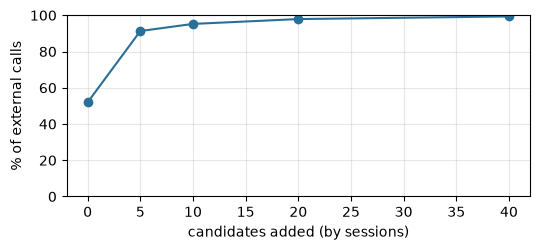

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 2.6))
ks = [0, 5, 10, 20, 40]
ys = [(base + cand.head(k).calls.sum()) / ext_calls * 100 for k in ks]
ax.plot(ks, ys, marker="o", color="#2a6f97"); ax.set_xlabel("candidates added (by sessions)"); ax.set_ylabel("% of external calls")
ax.set_ylim(0, 100); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## The repo's own tools

Sub-names behind `node`, `npm`, `npx`, `python`, `uv`: what the sessions ran through an interpreter. Context only:
these are the repo's scripts, not programs to write manifests for.

In [9]:
s = subs[subs.name.notna()].sort_values(["sessions", "calls"], ascending=False)
print(f"sub-names folded into (other): {int(T('subnames_other').iloc[0].names)} names, {int(T('subnames_other').iloc[0].calls)} calls")
pd.concat({i: g.head(10)[["name", "calls", "sessions"]].reset_index(drop=True) for i, g in s.groupby("interp") if g.calls.sum() >= 50}, axis=0)

sub-names folded into (other): 1021 names, 3675 calls


name  calls  sessions
node    0   merge-when-green   1750        49
        1    check-doc-links   1354        44
        2               test   2109        42
        3              index    459        39
        4         test-cover    297        37
        5         test-index    339        31
        6              build    961        30
        7        check-jsdoc    154        25
        8        check-state    176        23
        9  check-agents-size     72        20
npm     0                 ci    256        42
        1               test    617        37
        2              build    774        35
        3          typecheck    106        12
        4      fetch-pyodide     35        11
        5  gen-export-schema     12         6
        6       check-format      8         5
        7            install      6         5
        8       gen-api-docs     16         3
        9               lint     13         2
npx     0                tsc   1331        35
        1         playwright    811        28
        2                tsx     25         8
        3           prettier      6         5
        4            esbuild     18         4
        5             eslint      3         3
python3 0                mut     33         4
        1             mutate     24         4
        2               mut2     12         3
        3          json.tool      6         3
        4              edit3      4         3
        5               docs      4         2
        6              drive      3         2
        7              build      2         2
        8              edit2      2         2
        9              edit4      2         2

## Wrappers

Counted separately; the program each ran is in the tables above.

In [10]:
wraps.sort_values(["sessions", "calls"], ascending=False)[["name", "calls", "sessions", "projects"]].reset_index(drop=True)

,name,calls,sessions,projects
0,timeout,343,27,4
1,xargs,147,27,5
2,time,111,18,4
3,nohup,50,9,2
4,env,40,5,2


## Denied calls

Recoverable, with limits. A refused `Bash` call comes back as an `is_error` tool_result with one of two fixed leading
phrases (the auto-mode classifier's refusal, or the user's rejection). A call that prompted and was APPROVED leaves
no marker, so "needed approval" is not recoverable, only "was blocked". The harness may refuse some calls before they
are recorded at all. A denied compound command adds one denial to every program in it, so read the column as "ran
in a command that was refused", not "this program was refused".

In [11]:
progs["denied"] = progs.denied_auto + progs.denied_user
print(f"denied Bash calls: auto-mode {corpus.denied_auto}, user {corpus.denied_user}, of {corpus.bash_tool_uses} ({(corpus.denied_auto + corpus.denied_user) / corpus.bash_tool_uses:.2%})")
d = progs[(progs.kind == "external") & (progs.denied > 0)].copy()
d["denied share"] = (d.denied / d.calls).map("{:.1%}".format)
d["has_manifest"] = d.has_manifest
d.sort_values("denied", ascending=False)[["name", "denied", "denied_auto", "denied_user", "calls", "denied share", "has_manifest"]].head(20).reset_index(drop=True)

denied Bash calls: auto-mode 70, user 11, of 73885 (0.11%)


,name,denied,denied_auto,denied_user,calls,denied share,has_manifest
0,git,118,103,15,46942,0.3%,True
1,gh,56,53,3,15713,0.4%,True
2,tail,44,40,4,18314,0.2%,True
3,grep,22,17,5,57676,0.0%,False
4,node,21,19,2,16985,0.1%,False
5,head,20,15,5,45127,0.0%,True
6,cat,13,13,0,9173,0.1%,True
7,npm,9,9,0,2760,0.3%,False
8,sed,8,6,2,24091,0.0%,False
9,rm,8,7,1,959,0.8%,True


## What the ranking says

The 14 existing manifests already cover about half of all external-program calls (52%), but that is almost all `head`, `tail`, `git`, `cat`, `ls` and `gh`. The uncovered mass is concentrated: grep, sed, node, python3 and npm alone take coverage to 91%, and the top 20 candidates to 98%. By calls that is dominated by `grep` (the most-run program of all) and `sed`; by sessions the ranking is the same head, with `sort`, `cut`, `mkdir`, `ln`, `awk`, `sleep`, `uniq`, `tr` and `date` next, each in 33 to 48 of 74 sessions.

`node`, `python3`, `npm` and `npx` are interpreters: a manifest for them is a different problem (what they run is in the repo-tools table, and it is the repo's own scripts), so the plain-text tools are the practical first batch: grep, sed, sort, cut, mkdir, ln, awk, sleep, uniq, tr, date.

The starting list from the idea sits much lower than the text tools. `ps` (rank 17) and `du` (18) are in 25 sessions each; `df`, `sysctl`, `lsof`, `uptime` and `vm_stat` are in 10 to 16 sessions; `memory_pressure` and `top` are in 4 and 3 sessions. None is zero. They are real but second-batch: a few hundred calls each against tens of thousands for the text tools.

Denial is rare (0.11% of Bash calls) and sits on programs that already have manifests (`git`, `gh`, `tail`); among the candidates `grep` and `node` lead in absolute count, and `pkill` has the highest share (about 3%). It does not change the order.

Caveats. Coverage runs only as far back as the transcript files exist on this machine (first call dates above), and
sessions in this repo dominate, so the list reflects what an agent does while developing window.ml: git, GitHub,
text tools and the repo's scripts. A task like diagnosing a slow machine would look different. Calls the harness
rejected before running may not be in the transcripts, so `denied` is a lower bound. A "call" is one simple command
after splitting, so a pipeline counts each stage, and a name seen in one session only is invisible by design.